In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

In [27]:

data={
    "Student":["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O"],
    "Study_Hours":[2,3,4,5,4,6,5,3,4,5,6,4,5,30,3]
}

df=pd.DataFrame(data)
print("original dataset")
print(df)

original dataset
   Student  Study_Hours
0        A            2
1        B            3
2        C            4
3        D            5
4        E            4
5        F            6
6        G            5
7        H            3
8        I            4
9        J            5
10       K            6
11       L            4
12       M            5
13       N           30
14       O            3


In [28]:
df["Study_Hours"].describe()

,Study_Hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


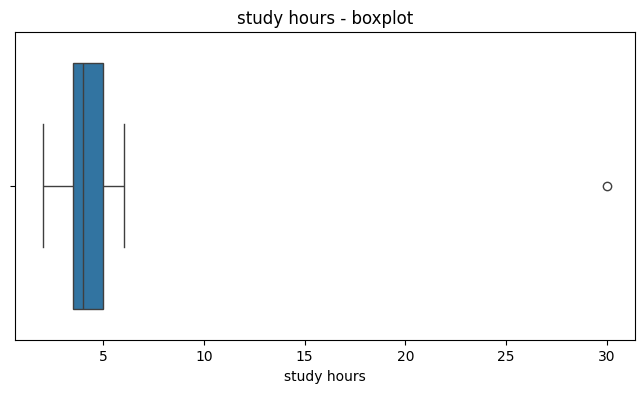

In [29]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Study_Hours"])
plt.title("study hours - boxplot")
plt.xlabel("study hours")
plt.show()

In [30]:
q1=df["Study_Hours"].quantile(0.25)
q3=df["Study_Hours"].quantile(0.75)

print("Q1 : ",q1)
print("Q3 : ",q3)

Q1 :  3.5
Q3 :  5.0


iqr:represents the middle 50%tile range of data

In [31]:
iqr=q3-q1
print("IQR : ",iqr)

IQR :  1.5


any value below the lower bound or upper bound is known as outlier

In [32]:
lower_bound=q1-1.5*iqr
upper_bound=q3+1.5*iqr

print("Lower bound: ",lower_bound)    #outlier
print("upper bound: ",upper_bound)


Lower bound:  1.25
upper bound:  7.25


In [33]:
outliers_iqr=df[
    (df["Study_Hours"]<lower_bound) |
    (df["Study_Hours"]>upper_bound)
]

print("IQR outliers")
display(outliers_iqr)

IQR outliers


,Student,Study_Hours
13,N,30


In [34]:
normal_data_iqr=df[
    (df["Study_Hours"]>=lower_bound) &
    (df["Study_Hours"]<=upper_bound)
]
display(normal_data_iqr)

,Student,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [36]:
df["Z_Score"]=zscore(df["Study_Hours"])

print("Dataset with Z-scores")
display(df)

Dataset with Z-scores


,Student,Study_Hours,Z_Score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [38]:
z_outliers=df[
    (df["Z_Score"] > 3) |
    (df["Z_Score"] < -3)
]

print("Z-score outliers")
display(z_outliers)

Z-score outliers


,Student,Study_Hours,Z_Score
13,N,30,3.687515


In [39]:
df_without_outliers=df[                        #complete removal of outlier
    (df["Study_Hours"] >= lower_bound) &
    (df["Study_Hours"] <= upper_bound)
]


display(df_without_outliers)

,Student,Study_Hours,Z_Score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [40]:
df_cappped=df.copy()           #replace outlier with boundary value->capping
df_cappped["Study_Hours"]=df_cappped["Study_Hours"].clip(
    lower=lower_bound,
    upper=upper_bound
)

display(df_cappped)

,Student,Study_Hours,Z_Score
0,A,2.00,-0.602669
1,B,3.00,-0.449448
2,C,4.00,-0.296227
3,D,5.00,-0.143006
4,E,4.00,-0.296227
5,F,6.00,0.010215
6,G,5.00,-0.143006
7,H,3.00,-0.449448
8,I,4.00,-0.296227
9,J,5.00,-0.143006


In [ ]:
print("original data")

print("after removing outliers")

print("after capping outliers")


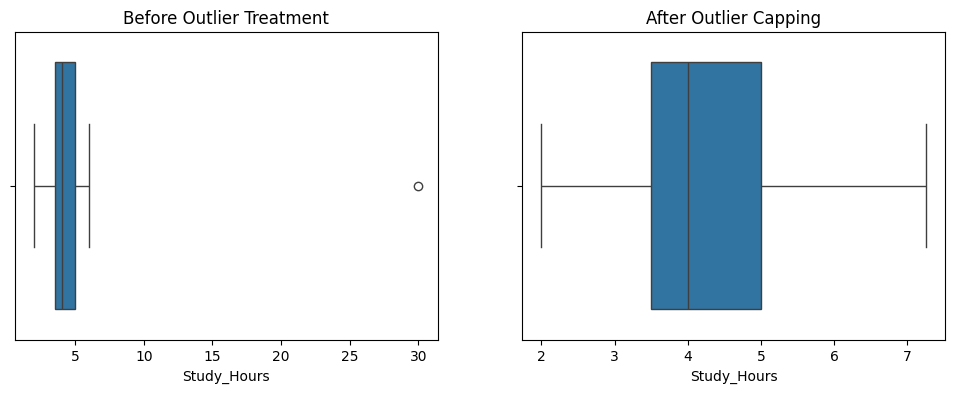

In [42]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df["Study_Hours"])
plt.title("Before Outlier Treatment")

plt.subplot(1, 2, 2)
sns.boxplot(x=df_cappped["Study_Hours"])
plt.title("After Outlier Capping")
plt.show()